In [1]:
import pandas as pd
from astropy.io.votable import parse
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

In [2]:
votable = parse("/home/pbautista/main/PhD/data/astrometry/Gaia-DR4-Prerelease-Astrometry/gaia-dr4-prerelease-epoch-astrometry_2026-06-26/GAIA_DR4_PRERELEASE_EPOCH_ASTROMETRY_RAW.xml")
table = votable.get_first_table().to_table()

In [3]:
# Choosing the BH3 source since its a nice example
source_id = 4318465066420528000 # BH3
# source = table[table["source_id"] == source_id]
# From astropy type to pandas data frame
df = table.to_pandas()
source = df[df["source_id"] == source_id]

In [4]:
def numeric_array(series):
    return np.asarray(
        [
            [
                np.nan if value is None or str(value) == "--" else float(value)
                for value in row
            ]
            for row in series
        ],
        dtype=float,
    )

def al_scan_direction(scan_pos_angle):
    """
    Return the unit vector along the Gaia along-scan direction.

    Parameters
    ----------
    scan_pos_angle : array-like
        Scan position angle in degrees.

    Returns
    -------
    ux, uy : ndarray
        Components of the AL unit vector in the sky plane:

        ux = sin(theta)
        uy = cos(theta)
    """
    theta = np.deg2rad(scan_pos_angle, dtype=float)

    return np.sin(theta), np.cos(theta)

In [5]:
scan = numeric_array(source['scan_pos_angle'])
centroid_al = numeric_array(source['centroid_pos_al'])
centroid_al_error = numeric_array(source['centroid_pos_error_al'])
centroid_ac = numeric_array(source['calculated_pos_ac'])
obs_times_tcb = numeric_array(source["obs_time_tcb"])
used_by_agis_al = numeric_array(source['used_by_agis_al'])
parallax_factor_al = np.asarray(source['parallax_factor_al'])
colour_factor_al =  numeric_array(source['colour_factor_al'])

In [6]:
reject = True

t_rel_year = (obs_times_tcb - obs_times_tcb.min()) / (
    365.25 * 86400 * 1e9
)

if reject == True:
    centroid_al_data = centroid_al * used_by_agis_al
    time_years_data = t_rel_year * used_by_agis_al


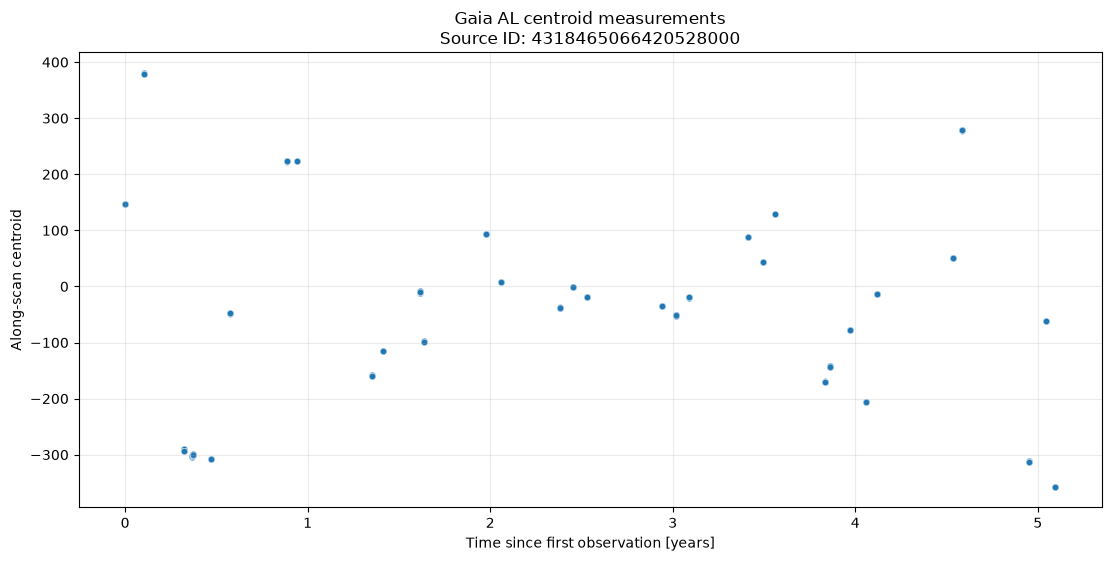

In [7]:
# Flatten the per-transit/per-sample arrays and keep only valid AGIS-used samples
x = t_rel_year.ravel()
y = centroid_al.ravel()
used = used_by_agis_al.ravel()

valid = (
    (used != 0)
    & np.isfinite(x)
    & np.isfinite(y)
)

fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)

ax.scatter(
    x[valid],
    y[valid],
    s=20,
    alpha=0.75,
    color="tab:blue",
    edgecolors="white",
    linewidths=0.3,
    rasterized=True,
)

ax.set_title(f"Gaia AL centroid measurements\nSource ID: {source_id}")
ax.set_xlabel("Time since first observation [years]")
ax.set_ylabel("Along-scan centroid")
ax.grid(True, alpha=0.25)
ax.ticklabel_format(axis="x", style="plain")

plt.show()

# I want to plot the model (of centroid pos) vs obs time

In [8]:
import sys
from pathlib import Path

project_src = Path(
    "/home/pbautista/main/PhD/data/astrometry/"
    "Gaia-DR4-Prerelease-Astrometry/gaia-dr4-explorer/src"
)

if not project_src.exists():
    raise FileNotFoundError(
        f"Could not find project source directory: {project_src}"
    )

if str(project_src) not in sys.path:
    sys.path.insert(0, str(project_src))

from gaia_dr4_explorer.products.astrometry.fitting import (
    fit_dr4_like_single_source,
)


In [9]:
import sys
import gaiasupdate

print(sys.executable)
print(gaiasupdate.__file__)
fit_result = fit_dr4_like_single_source(table, source_id,)

/home/pbautista/main/PhD/data/astrometry/.venv/bin/python
/home/pbautista/main/PhD/data/astrometry/.venv/lib/python3.12/site-packages/gaiasupdate/__init__.py
The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.

Please note the archive will be unavailable on 15 October at 12 CEST for maintenance purposes. Apologies for the inconveniences.


In [10]:
print(fit_result.model)
print(fit_result.parameter_names)
print(fit_result.parameters)
print(fit_result.parameter_errors)
print(fit_result.n_measurements)

6p_constrained_colour
('delta_alpha_star', 'delta_delta', 'parallax', 'pmra_star', 'pmdec', 'pseudocolour_term')
[-2.19648400e-05 -3.39066070e-04  1.96075054e+00 -3.07396158e+01
 -1.48926288e+02  2.96073423e-05]
[4.27112141e-01 3.78192569e-01 5.21311619e-01 2.90491792e-01
 2.24649279e-01 6.26985569e-05]
558


In [11]:
parameter_values = dict(
    zip(
        fit_result.parameter_names,
        fit_result.parameters,
        strict=True,
    )
)

parameter_values

{'delta_alpha_star': -2.1964840044251793e-05,
 'delta_delta': -0.000339066070403931,
 'parallax': 1.9607505390550184,
 'pmra_star': -30.739615768193133,
 'pmdec': -148.926288297854,
 'pseudocolour_term': 2.960734233411045e-05}

In [12]:
# scan_flat = scan.flatten()
# centroid_al_flat = centroid_al.flatten()
# centroid_al_error_flat = centroid_al_error.flatten()
# used_by_agis_al_flat = used_by_agis_al.flatten()
# parallax_factor_al_flat = parallax_factor_al.flatten()
# t_rel_year_flat = t_rel_year.flatten()

In [13]:
parameter_values = dict(
    zip(
        fit_result.parameter_names,
        fit_result.parameters,
        strict=True,
    )
)

delta_alpha_star = parameter_values["delta_alpha_star"]
delta_delta = parameter_values["delta_delta"]
parallax = parameter_values["parallax"]
pmra_star = parameter_values["pmra_star"]
pmdec = parameter_values["pmdec"]
pseudocolour_term = parameter_values["pseudocolour_term"]

In [14]:
s, c = al_scan_direction(scan)

# model_centroid_al = (
#     delta_alpha_star * s
#     + delta_delta * c
#     + parallax * parallax_factor_al
#     + pmra_star * t_rel_year * s
#     + pmdec * t_rel_year * c
#     #+ pseudocolour_term * colour_factor_al
# )

In [15]:
parallax_factor_al = np.broadcast_to(
    np.asarray(parallax_factor_al)[:, None],
    (77,10),
)

# colour_factor_al_reshaped = np.broadcast_to(
#     np.asarray(colour_factor_al)[:, None],
#     (77,10),
# )


variables = {
    "delta_alpha_star": delta_alpha_star,
    "s": s,
    "delta_delta": delta_delta,
    "c": c,
    "parallax": parallax,
    "parallax_factor_al": parallax_factor_al,
    "pmra_star": pmra_star,
    "t_rel_year": t_rel_year,
    "pmdec": pmdec,
    "colour_factor_al": colour_factor_al
}

for name, value in variables.items():
    print(f"{name:20s}: {np.shape(value)}")


# Expand the one-value-per-transit parallax factor to one value per sample.



model_centroid_al = (
    delta_alpha_star * s
    + delta_delta * c
    + parallax * parallax_factor_al
    + pmra_star * t_rel_year * s
    + pmdec * t_rel_year * c
    + pseudocolour_term * colour_factor_al
)

# print(model_centroid_al.shape)
# print((model_centroid_al[0]))

delta_alpha_star    : ()
s                   : (77, 10)
delta_delta         : ()
c                   : (77, 10)
parallax            : ()
parallax_factor_al  : (77, 10)
pmra_star           : ()
t_rel_year          : (77, 10)
pmdec               : ()
colour_factor_al    : (77, 10)


(770,) (770,) (770,)
64.31013562402703


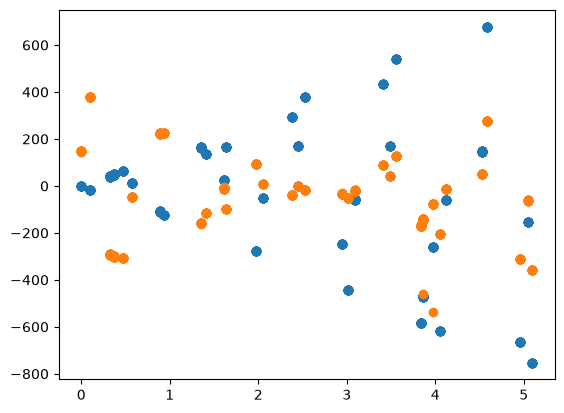

In [16]:
t = t_rel_year.flatten()
y_model = model_centroid_al.flatten()
y_obs = centroid_al.flatten()
print(t.shape, y_model.shape, y_obs.shape)
plt.scatter(t, y_model)
plt.scatter(t, y_obs)
print(y_model[769])

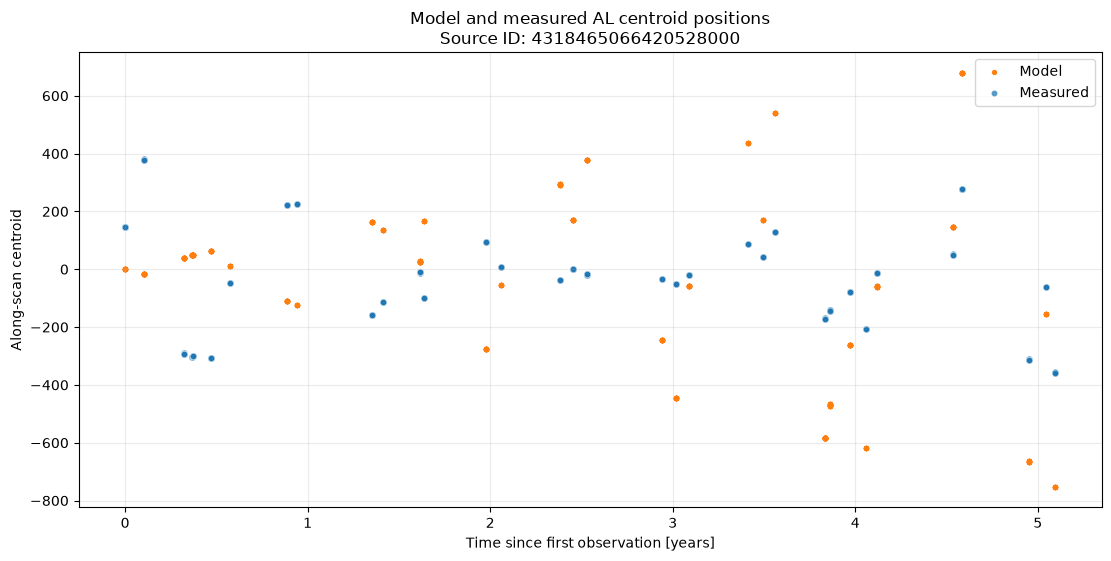

In [17]:
# Flatten the 77 x 10 arrays for plotting
time_flat = np.asarray(t_rel_year).ravel()
model_flat = np.asarray(model_centroid_al).ravel()
measured_flat = np.asarray(centroid_al).ravel()
used_flat = np.asarray(used_by_agis_al).ravel()

valid_model = (
    (used_flat != 0)
    & np.isfinite(time_flat)
    & np.isfinite(model_flat)
)

valid_measured = (
    (used_flat != 0)
    & np.isfinite(time_flat)
    & np.isfinite(measured_flat)
)

model_order = np.argsort(time_flat[valid_model])

fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)

ax.scatter(
    time_flat[valid_model][model_order],
    model_flat[valid_model][model_order],
    s=8,
    color="tab:orange",
    label="Model",
)

ax.scatter(
    time_flat[valid_measured],
    measured_flat[valid_measured],
    s=20,
    alpha=0.75,
    color="tab:blue",
    edgecolors="white",
    linewidths=0.3,
    label="Measured",
)

ax.set_title(f"Model and measured AL centroid positions\nSource ID: {source_id}")
ax.set_xlabel("Time since first observation [years]")
ax.set_ylabel("Along-scan centroid")
ax.grid(True, alpha=0.25)
ax.ticklabel_format(axis="x", style="plain")
ax.legend()

plt.show()

## Corrected

The issue with the above is that I used the wrong time comp


In [18]:
display(ccd)
print(type(ccd))

NameError: name 'ccd' is not defined

In [ ]:
votable = parse("/home/pbautista/main/PhD/data/astrometry/Gaia-DR4-Prerelease-Astrometry/gaia-dr4-prerelease-epoch-astrometry_2026-06-26/GAIA_DR4_PRERELEASE_EPOCH_ASTROMETRY_RAW.xml")
table = votable.get_first_table().to_table()

In [ ]:
# functions taken from the explorer
from gaia_dr4_explorer.products.astrometry.fitting import fit_dr4_like_single_source # is a look up function for the best fit parameters of each source.
from gaia_dr4_explorer.products.astrometry.normalize import normalize_epoch_astrometry # see below

# The normalize_epoch_astrometry function, transforms the data into a convinient tabulated data set for plotting and computing model values.
# e.g. instead of using the time of observation in nanoseconds it gives you the time in years relative to a reference time (J2017.5).

source_id = 2237987199365376 # here you can choose which source you want to look at. Will make this into some dict with all 12 sources.

# Keep the published transit rows as an Astropy table and normalize them once.
source_table = table[table["source_id"] == source_id]  # table comes form VOTable 
normalized = normalize_epoch_astrometry(source_table) # gives you a nice data frames
ccd = normalized.ccd # convinient table for plotting all CCD centroid_pos_al

# The normalized table preserves the published CCD ordering and broadcasts
# transit-level quantities to the corresponding ten CCD observations.
def ccd_float(column_name):
    return np.asarray(np.ma.filled(ccd[column_name], np.nan), dtype=float)

# pull data from table as numpy array
centroid_model_obs = ccd_float("centroid_pos_al")
scan_model_deg = ccd_float("scan_pos_angle")
time_model_year = ccd_float("relative_time_year")
parallax_factor_model = ccd_float("parallax_factor_al")
colour_factor_raw = ccd_float("colour_factor_al")
used_model = np.asarray(
    np.ma.filled(ccd["used_by_agis_al"], False),
    dtype=bool,
)

# gaiasupdate converts the archive colour factor before fitting.
colour_factor_model = -1e3 * colour_factor_raw

# Apply the same finite-data requirements as the model calculation. This is
# Boolean filtering; multiplying by the mask would create artificial zeros.
model_mask = (
    used_model
    & np.isfinite(centroid_model_obs)
    & np.isfinite(scan_model_deg)
    & np.isfinite(time_model_year)
    & np.isfinite(parallax_factor_model)
    & np.isfinite(colour_factor_model)
)

if not np.any(model_mask):
    raise ValueError("No finite AGIS-used CCD observations are available.")

fit_result = fit_dr4_like_single_source(table, source_id)   
parameters = dict(
    zip(fit_result.parameter_names, fit_result.parameters, strict=True)
)

theta_model = np.deg2rad(scan_model_deg[model_mask])
t_model = time_model_year[model_mask]

model_centroid_al = (
    parameters["delta_alpha_star"] * np.sin(theta_model)
    + parameters["delta_delta"] * np.cos(theta_model)
    + parameters["parallax"] * parallax_factor_model[model_mask]
    + parameters["pmra_star"] * t_model * np.sin(theta_model)
    + parameters["pmdec"] * t_model * np.cos(theta_model)
    + parameters["pseudocolour_term"] * colour_factor_model[model_mask]
)

observed_centroid_al = centroid_model_obs[model_mask]
manual_residuals = observed_centroid_al - model_centroid_al

print(f"CCD slots: {len(ccd)}")
print(f"AGIS-used finite CCD observations: {model_mask.sum()}")
print(f"Official fit measurements: {fit_result.n_measurements}")
print(f"Manual residual RMS: {np.sqrt(np.mean(manual_residuals**2)):.6f} mas")
print(f"Official residual RMS: {np.sqrt(np.mean(fit_result.residuals**2)):.6f} mas")

# This is the definitive alignment check: the manual model must reproduce
# the residuals returned by gaiasupdate, not merely resemble the data plot.
if model_mask.sum() != len(fit_result.residuals):
    raise ValueError(
        "The normalized CCD mask does not match the observations retained by "
        f"the fit ({model_mask.sum()} versus {len(fit_result.residuals)})."
    )

max_residual_difference = np.max(
    np.abs(manual_residuals - fit_result.residuals)
)
print(f"Maximum manual/official residual difference: {max_residual_difference:.3e} mas")

if not np.allclose(manual_residuals, fit_result.residuals, rtol=0.0, atol=1e-7):
    raise ValueError(
        "The manually reconstructed model does not reproduce the official fit."
    )


CCD slots: 880
AGIS-used finite CCD observations: 702
Official fit measurements: 702
Manual residual RMS: 3.975862 mas
Official residual RMS: 3.975862 mas
Maximum manual/official residual difference: 2.007e-13 mas


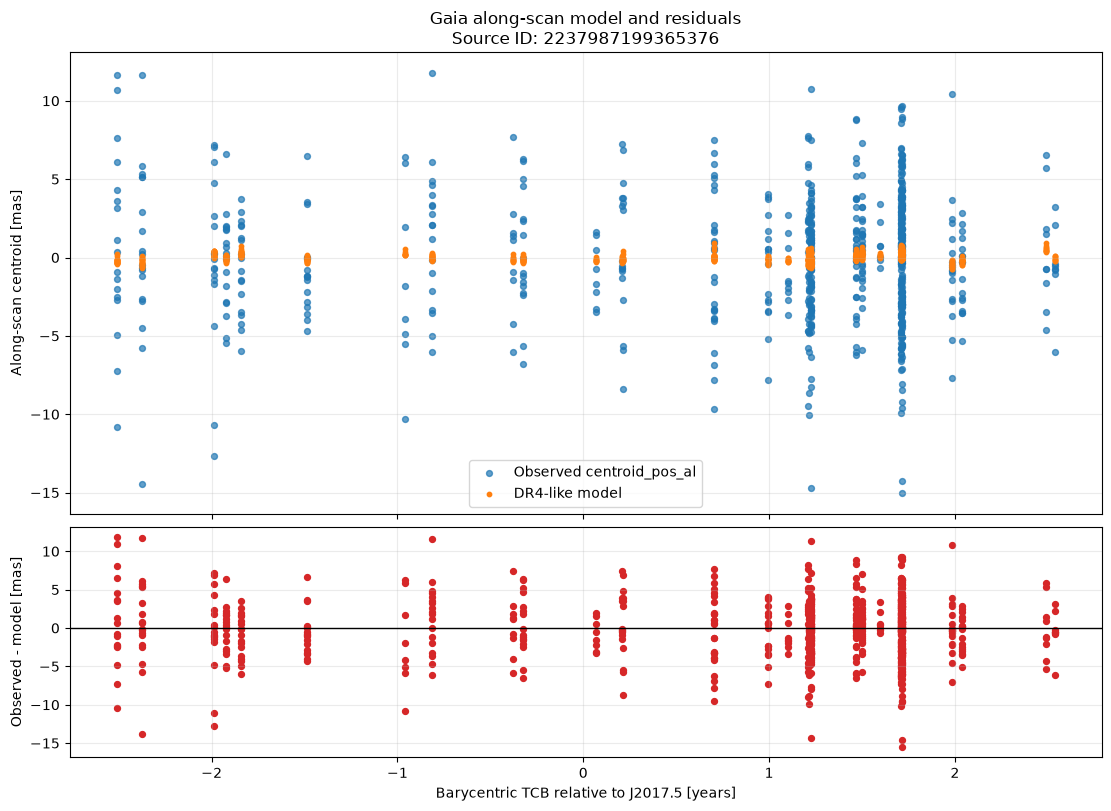

In [ ]:
order = np.argsort(t_model)

fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 8),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": (2, 1)},
)

axes[0].scatter(
    t_model[order],
    observed_centroid_al[order],
    s=18,
    alpha=0.7,
    color="tab:blue",
    label="Observed centroid_pos_al",
)
axes[0].scatter(
    t_model[order],
    model_centroid_al[order],
    s=10,
    color="tab:orange",
    label="DR4-like model",
)
axes[0].set_ylabel("Along-scan centroid [mas]")
axes[0].set_title(f"Gaia along-scan model and residuals\nSource ID: {source_id}")
axes[0].legend()
axes[0].grid(True, alpha=0.25)

axes[1].axhline(0.0, color="black", linewidth=1)
axes[1].scatter(
    t_model[order],
    manual_residuals[order],
    s=18,
    color="tab:red",
)
axes[1].set_xlabel("Barycentric TCB relative to J2017.5 [years]")
axes[1].set_ylabel("Observed - model [mas]")
axes[1].grid(True, alpha=0.25)

plt.show()
